# Pós-Processamento, Auditoria e Visualização dos Artefatos (Padrão Jubiaba & VU13P KKT)
## Análise Estatística, Preços de Sombra ($\mu_j$) e Consumo na FPGA Virtex UltraScale+ VU13P para a Topologia `v2` (25 Anéis)

Este notebook atua como o equivalente ao `Results_CNN_L0Ringer.py` do `codeTCC`, operando de forma **100% desacoplada do treinamento**. Ele lê diretamente os artefatos estruturados no padrão **Jubiaba**:

```text
results/<dataset_prefix>/<model_name>/iet{iet}/ieta{ieta}/v{version}/
├── saved_models/  # model_v{V}_f{F}_r{R}.keras, best_model.keras, best_model.onnx
├── plots/         # Gráficos em alta resolução (300 DPI), incluindo kkt_primal_dual_evolution.png
├── history/       # training_history.csv, history.json
├── metadata/      # training_metadata_v{V}.pkl/.json, cross_validation_results.csv, reproducibility_metadata.json, kkt_allocation_results.json
└── evaluation/    # holdout_test_set.npz, holdout_predictions.npz
```


In [1]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"
import sys
import json
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

repo_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.exists(os.path.join(repo_root, 'src')):
    repo_root = os.path.abspath(os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

# Seleção do Experimento a Inspecionar
EXPORT_DIR = os.path.join(repo_root, "results")
DATASET_PREFIX = "mc21_13p6TeV.Zee.JF17.2sigma.5M"
MODEL_NAME = "QCNN1D_KKT"
IET = 5
IETA = 0
VERSION = 2  # 2 -> 25 Anéis, 1 -> 50 Anéis, 0 -> 100 Anéis

base_dir = os.path.join(EXPORT_DIR, DATASET_PREFIX, MODEL_NAME, f"iet{IET}", f"ieta{IETA}", f"v{VERSION}")
print(f"Inspecionando diretório Jubiaba:\n  -> {base_dir}")
assert os.path.isdir(base_dir), f"Diretório não encontrado: {base_dir}"


Inspecionando diretório Jubiaba:
  -> /home/iaraujo/Documentos/Github/cnn-optimization/results/mc21_13p6TeV.Zee.JF17.2sigma.5M/QCNN1D_KKT/iet5/ieta0/v2


## 1. Metadados de Reprodutibilidade, Limites da FPGA VU13P e Alocação Primal-Dual (KKT)

Carregamos `reproducibility_metadata.json` e `kkt_allocation_results.json` da pasta `metadata/`.


In [2]:
repro_path = os.path.join(base_dir, "metadata", "reproducibility_metadata.json")
kkt_path = os.path.join(base_dir, "metadata", "kkt_allocation_results.json")

with open(repro_path, "r", encoding="utf-8") as f:
    repro_meta = json.load(f)

with open(kkt_path, "r", encoding="utf-8") as f:
    kkt_meta = json.load(f)

print("=== Metadados de Reprodutibilidade ===")
print(f"  • Timestamp       : {repro_meta['timestamp']}")
print(f"  • Git Commit      : {repro_meta['git_commit']}")
print(f"  • Região Cinemática: IET={repro_meta['iet']}, IETA={repro_meta['ieta']} | Versão: v{repro_meta['version']}")
print(f"  • Estrutura Anéis : {repro_meta['extra_config'].get('rings_structure')}")
print(f"  • Diagnóstico KKT : {kkt_meta.get('kkt_stopping_diagnostics')}")

kkt_rows = []
hw_q = repro_meta["extra_config"]["hardware_qkeras_kkt"]
for layer_info in hw_q["breakdown"]:
    lname = layer_info["layer_name"]
    kkt_rows.append({
        "Camada": lname,
        "Tipo": layer_info["layer_type"],
        "Unidades (n_l)": layer_info.get("units", "-"),
        "Parâmetros": layer_info["params"],
        "MACs": layer_info["macs"],
        "Bits Contínuos (KKT)": round(kkt_meta["continuous_bits"][lname], 3),
        "Bits Pesos (w_l)": layer_info["b_w"],
        "Bits Ativação (a_l)": layer_info["b_a"],
        "BOPs": layer_info["bops"],
        "VU13P DSP": int(layer_info.get("DSP", 0)),
        "VU13P LUT": round(float(layer_info.get("LUT", 0.0)), 1),
        "VU13P FF": round(float(layer_info.get("FF", 0.0)), 1),
        "VU13P BRAM [bits]": int(layer_info.get("BRAM_bits", 0)),
    })

df_kkt = pd.DataFrame(kkt_rows)
print("\n=== Tabela de Quantização por Camada e Recursos na FPGA Virtex UltraScale+ VU13P ===")
display(df_kkt)


=== Metadados de Reprodutibilidade ===
  • Timestamp       : 2026-11-09T22:24:36.520269
  • Git Commit      : 99fdc96c3f05717dc730627fbf1e5b7359ec6a25
  • Região Cinemática: IET=5, IETA=0 | Versão: v2
  • Estrutura Anéis : {'PS': 2, 'EM1': 16, 'EM2': 2, 'EM3': 2, 'HAD1': 1, 'HAD2': 1, 'HAD3': 1}
  • Diagnóstico KKT : {'converged': True, 'sp_converged': True, 'sp_change': 0.0, 'primal_feasible': True, 'dual_feasible': True, 'complementary_slackness': True, 'slackness_products': {'DSP': 0.0, 'LUT': 0.0, 'FF': 0.0, 'BRAM_bits': 0.0}}

=== Tabela de Quantização por Camada e Recursos na FPGA Virtex UltraScale+ VU13P ===


,Camada,Tipo,Unidades (n_l),Parâmetros,MACs,Bits Contínuos (KKT),Bits Pesos (w_l),Bits Ativação (a_l),BOPs,VU13P DSP,VU13P LUT,VU13P FF,VU13P BRAM [bits]
0,conv1d_1,QConv1D,8,32,600,2.734,2,8,9600,0,533.3,364.0,64
1,dense_1,QDense,8,776,768,5.167,5,8,30720,0,1706.7,4264.0,3880
2,output_dense,QDense,1,9,8,2.000,8,8,512,0,28.4,76.0,72


## 2. Desempenho Estatístico em Validação Cruzada ($K$-Folds)

Analisamos os resultados salvos em `metadata/cross_validation_results.csv`.


In [3]:
cv_csv_path = os.path.join(base_dir, "metadata", "cross_validation_results.csv")
df_cv = pd.read_csv(cv_csv_path)

df_cv_display = df_cv.copy()
for col in ["sp_max", "pd_knee", "fa_knee", "auc"]:
    df_cv_display[col] = (df_cv_display[col] * 100.0).round(2)

display(df_cv_display)

summary_stats = pd.DataFrame({
    "Métrica": ["Índice SP [%]", "Prob. Detecção - PD [%]", "Falso Alarme - FA [%]", "AUC ROC [%]"],
    "Média": [
        df_cv["sp_max"].mean() * 100,
        df_cv["pd_knee"].mean() * 100,
        df_cv["fa_knee"].mean() * 100,
        df_cv["auc"].mean() * 100,
    ],
    "Desvio Padrão": [
        df_cv["sp_max"].std() * 100,
        df_cv["pd_knee"].std() * 100,
        df_cv["fa_knee"].std() * 100,
        df_cv["auc"].std() * 100,
    ],
    "Melhor Fold": [
        df_cv["sp_max"].max() * 100,
        df_cv.loc[df_cv["sp_max"].idxmax(), "pd_knee"] * 100,
        df_cv.loc[df_cv["sp_max"].idxmax(), "fa_knee"] * 100,
        df_cv["auc"].max() * 100,
    ],
}).round(2)

print("\n=== Resumo Estatístico dos Folds ===")
display(summary_stats)


,fold,repeat,sp_max,pd_knee,fa_knee,threshold_knee,auc,best_epoch,model_path
0,1,1,97.69,98.65,3.27,0.998335,99.35,1,model_v2_f1_r1.keras
1,2,1,97.54,98.56,3.47,0.789315,99.40,12,model_v2_f2_r1.keras
2,3,1,97.48,98.91,3.94,0.998263,99.40,1,model_v2_f3_r1.keras
3,4,1,97.93,98.90,3.03,0.664323,99.49,8,model_v2_f4_r1.keras
4,5,1,97.78,99.08,3.52,0.713831,99.41,8,model_v2_f5_r1.keras



=== Resumo Estatístico dos Folds ===


,Métrica,Média,Desvio Padrão,Melhor Fold
0,Índice SP [%],97.68,0.18,97.93
1,Prob. Detecção - PD [%],98.82,0.21,98.90
2,Falso Alarme - FA [%],3.45,0.34,3.03
3,AUC ROC [%],99.41,0.05,99.49


## 3. Auditoria Independente a partir de `evaluation/holdout_predictions.npz`

Verificamos as predições brutas armazenadas em disco nos pontos de operação padrão do trigger ATLAS (`Tight`, `Medium`, `Loose`, `Very Loose`).


In [4]:
from sklearn.metrics import roc_curve
from src.metrics import compute_sp_with_threshold

preds_npz = np.load(os.path.join(base_dir, "evaluation", "holdout_predictions.npz"))
y_true_ho = preds_npz["y_true"]
y_pred_ho = preds_npz["y_pred"]
saved_thresh = float(preds_npz["threshold"][0])

sp_ho, pd_ho, fa_ho, thresh_ho, _ = compute_sp_with_threshold(y_true_ho, y_pred_ho)
fa_curve, pd_curve, thresholds = roc_curve(y_true_ho, y_pred_ho)

wp_targets = [
    ("Knee SP (Ótimo)", pd_ho),
    ("Tight (PD = 96.0%)", 0.960),
    ("Medium (PD = 97.5%)", 0.975),
    ("Loose (PD = 98.5%)", 0.985),
    ("Very Loose (PD = 99.0%)", 0.990),
]

wp_rows = []
for wp_name, target_pd in wp_targets:
    idx = int(np.argmin(np.abs(pd_curve - target_pd)))
    wp_rows.append({
        "Ponto de Operação": wp_name,
        "PD Alvo [%]": round(target_pd * 100, 2),
        "PD Realizado [%]": round(float(pd_curve[idx]) * 100, 2),
        "Falso Alarme - FA [%]": round(float(fa_curve[idx]) * 100, 2),
        "Rejeição de Jatos (1-FA) [%]": round((1.0 - float(fa_curve[idx])) * 100, 2),
        "Limiar de Decisão": round(float(thresholds[idx]), 4),
    })

df_wp = pd.DataFrame(wp_rows)
display(df_wp)


2026-11-09 22:24:44.766206: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-09 22:24:44.766484: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-09 22:24:44.800703: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


2026-11-09 22:24:45.657639: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-09 22:24:45.657889: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


,Ponto de Operação,PD Alvo [%],PD Realizado [%],Falso Alarme - FA [%],Rejeição de Jatos (1-FA) [%],Limiar de Decisão
0,Knee SP (Ótimo),98.37,98.37,2.77,97.23,0.7346
1,Tight (PD = 96.0%),96.00,95.98,2.04,97.96,0.8311
2,Medium (PD = 97.5%),97.50,97.51,2.44,97.56,0.7750
3,Loose (PD = 98.5%),98.50,98.50,2.99,97.01,0.7170
4,Very Loose (PD = 99.0%),99.00,99.00,3.62,96.38,0.6407


## 4. Galeria Completa de Visualizações (`plots/`)

Exibimos todas as 10 figuras científicas geradas na pasta `plots/` do experimento, incluindo a evolução Primal-Dual KKT e os Multiplicadores de Lagrange ($\mu_j$).



--- rings_profile_v2.png ---


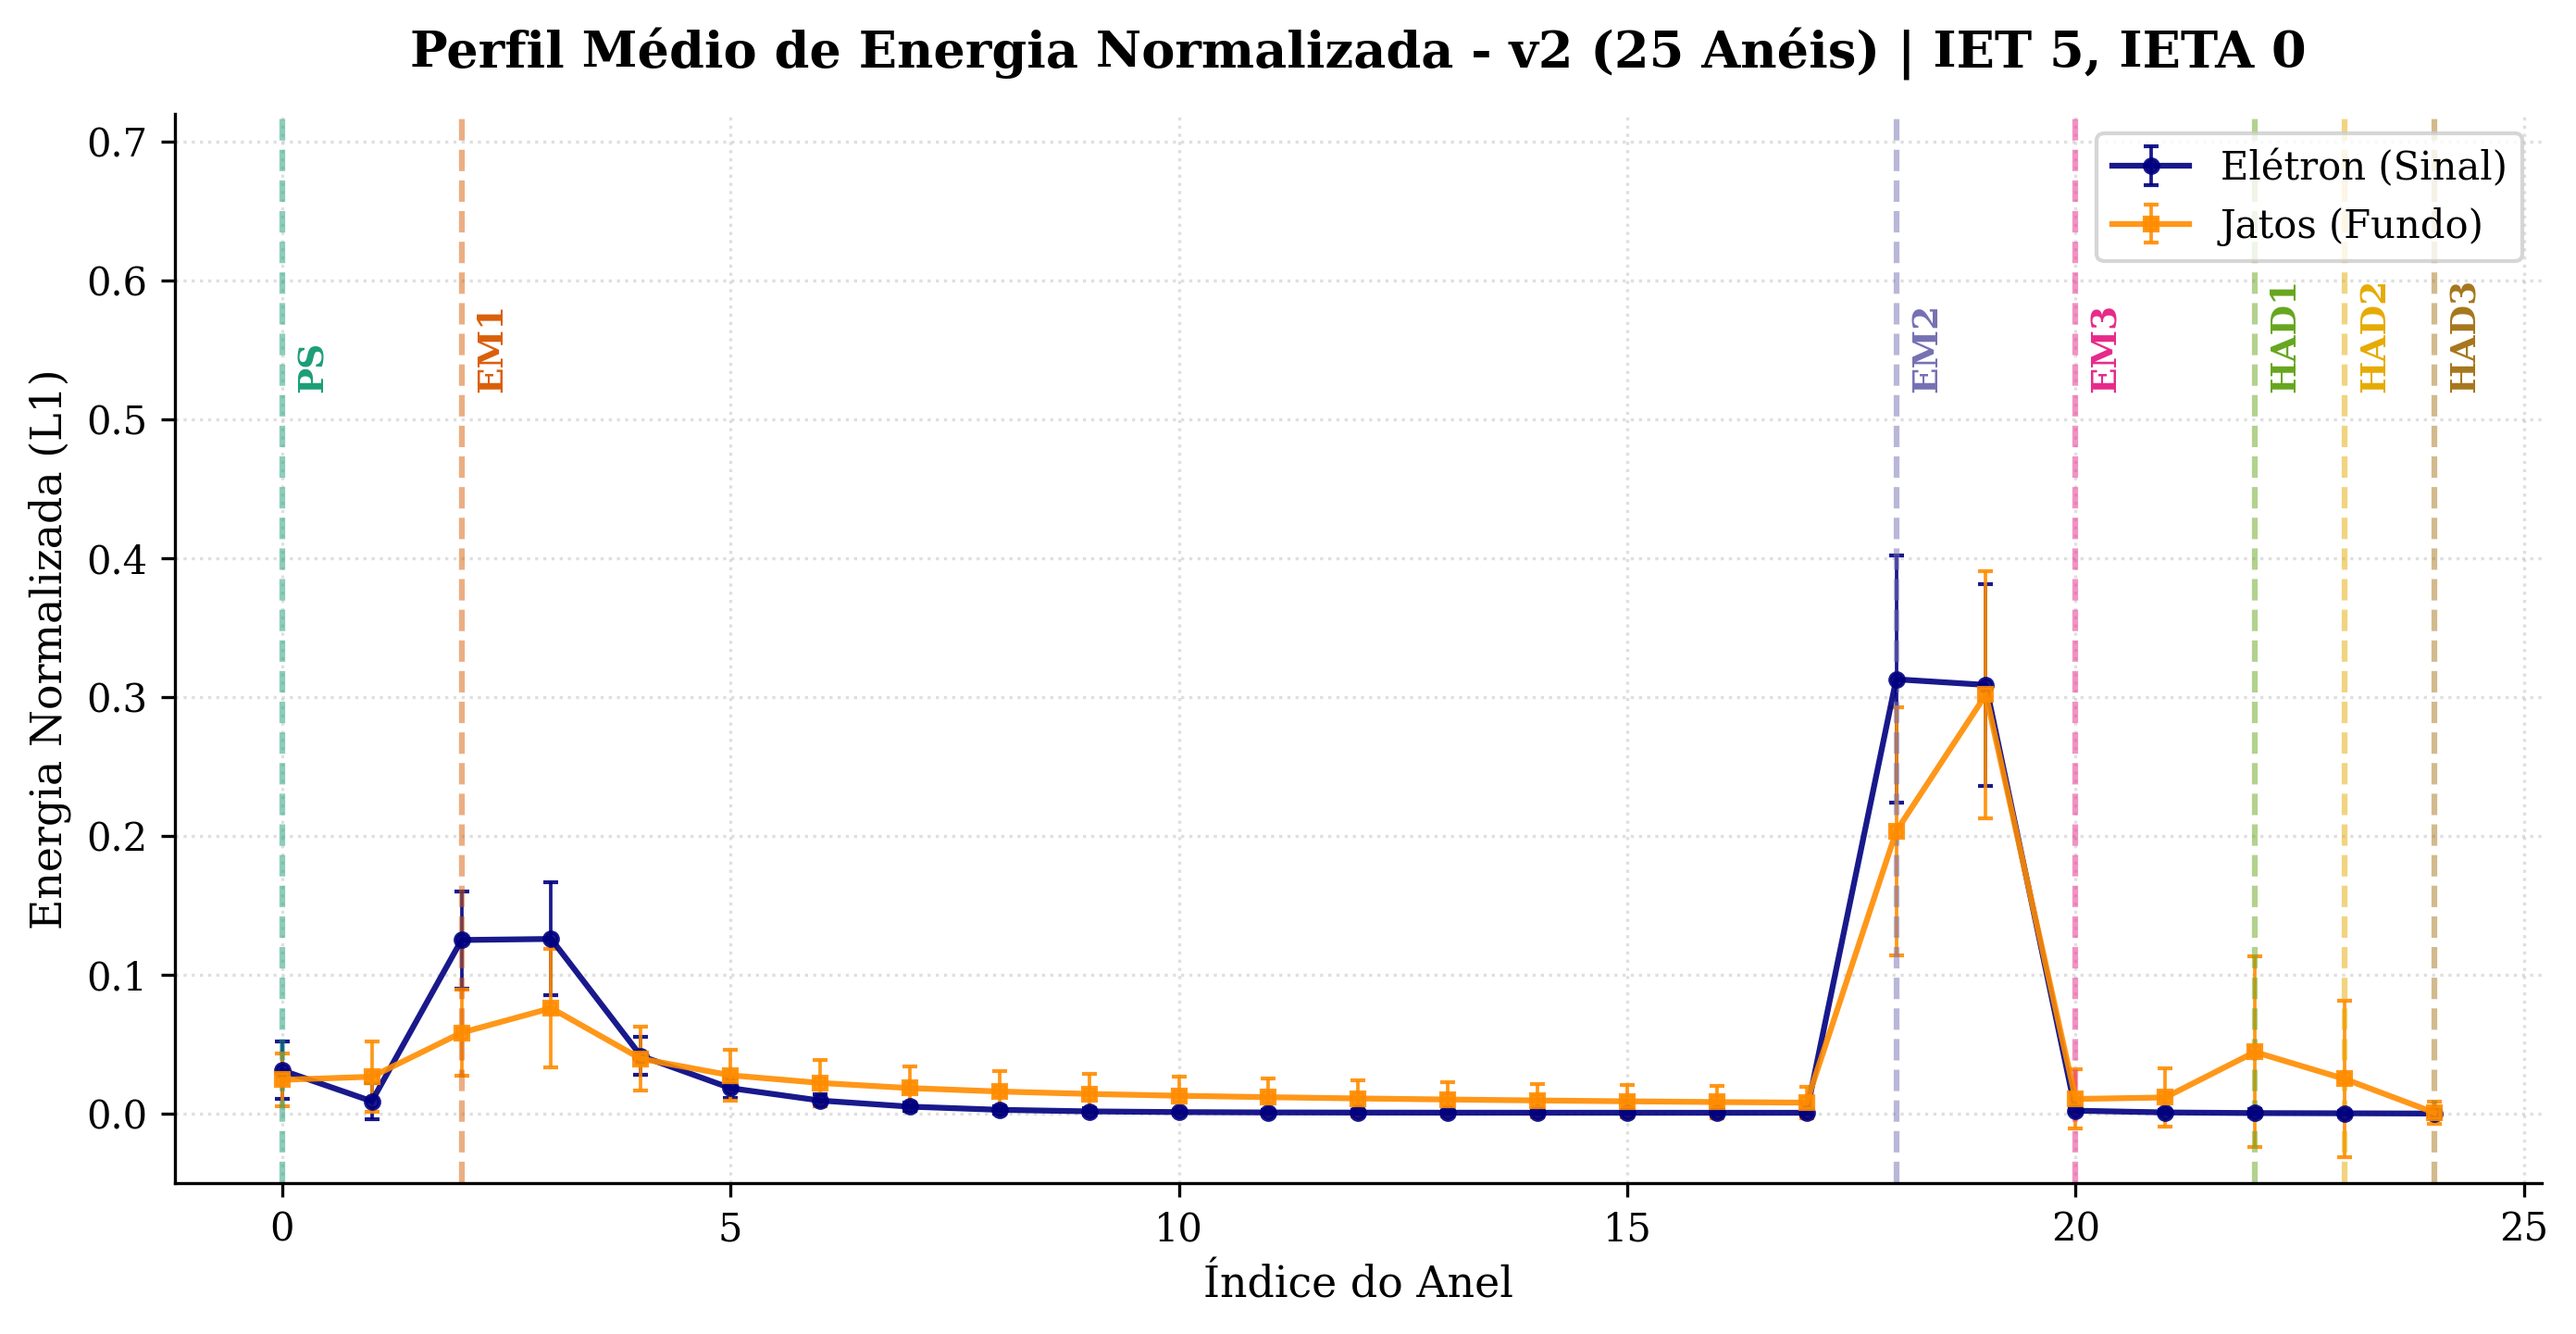


--- kkt_primal_dual_evolution.png ---


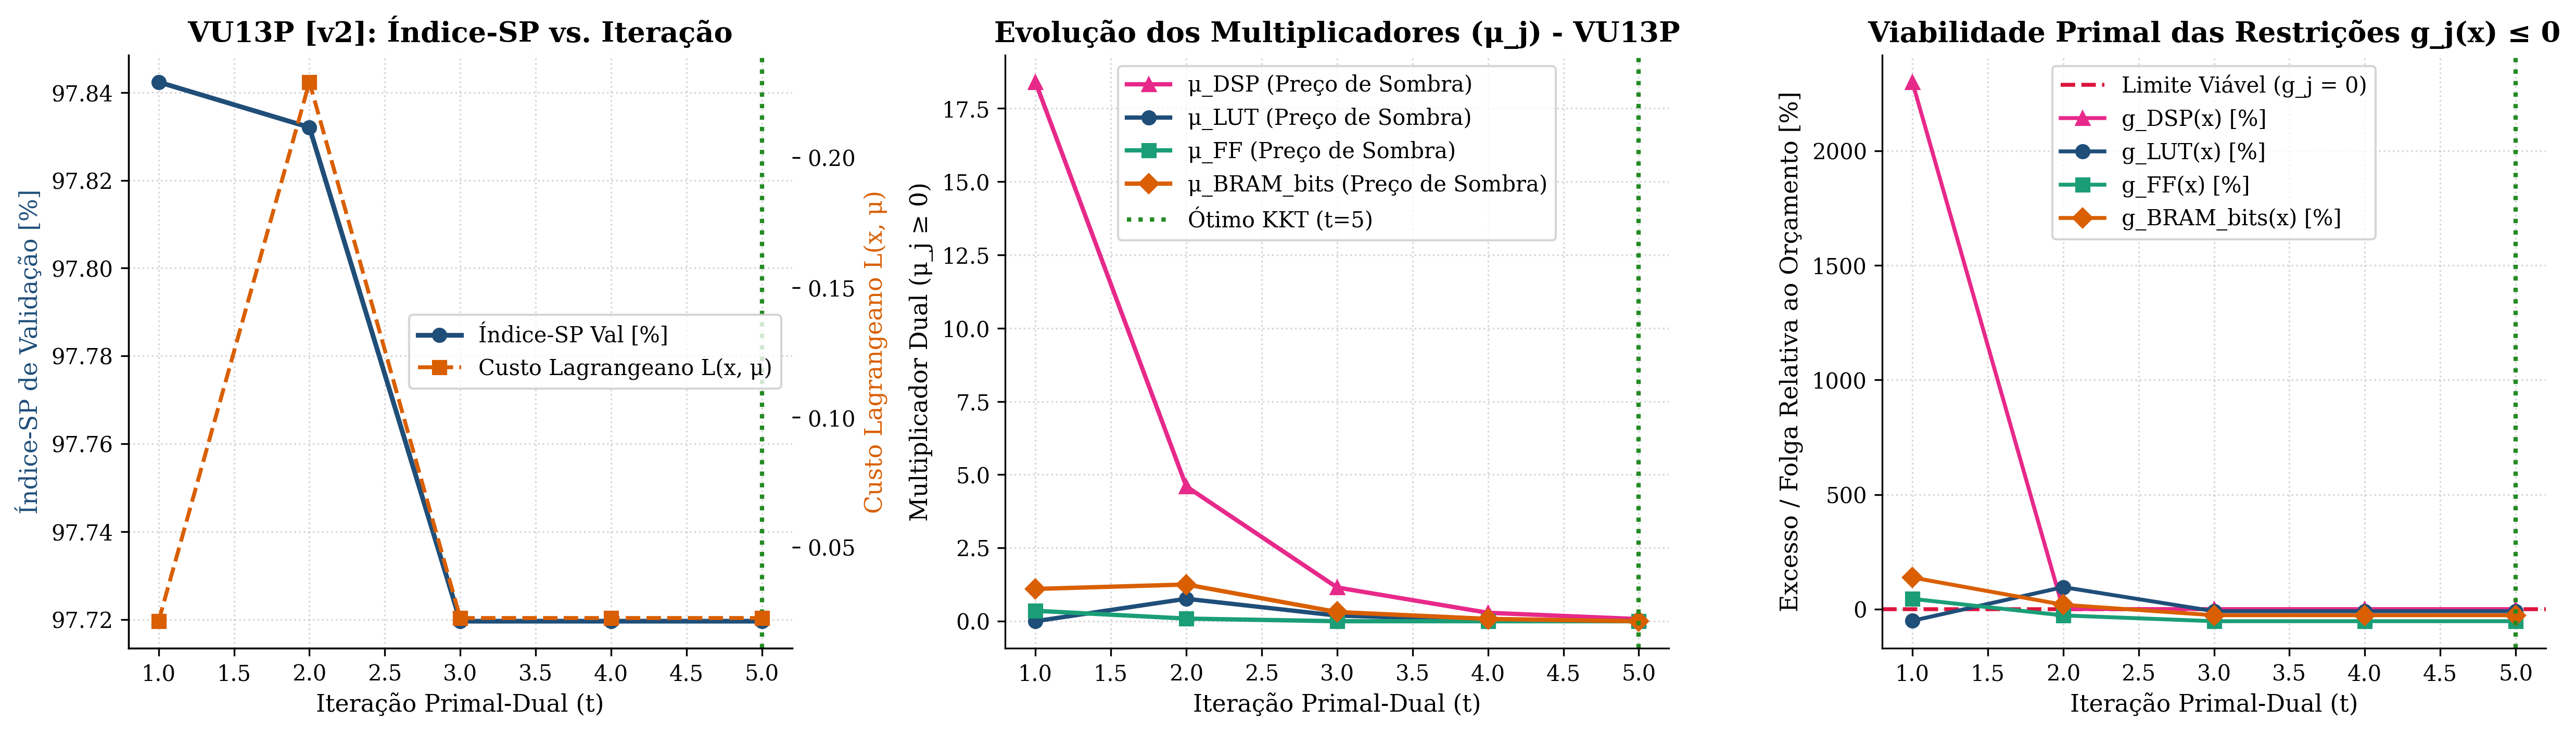


--- vu13p_resource_utilization.png ---


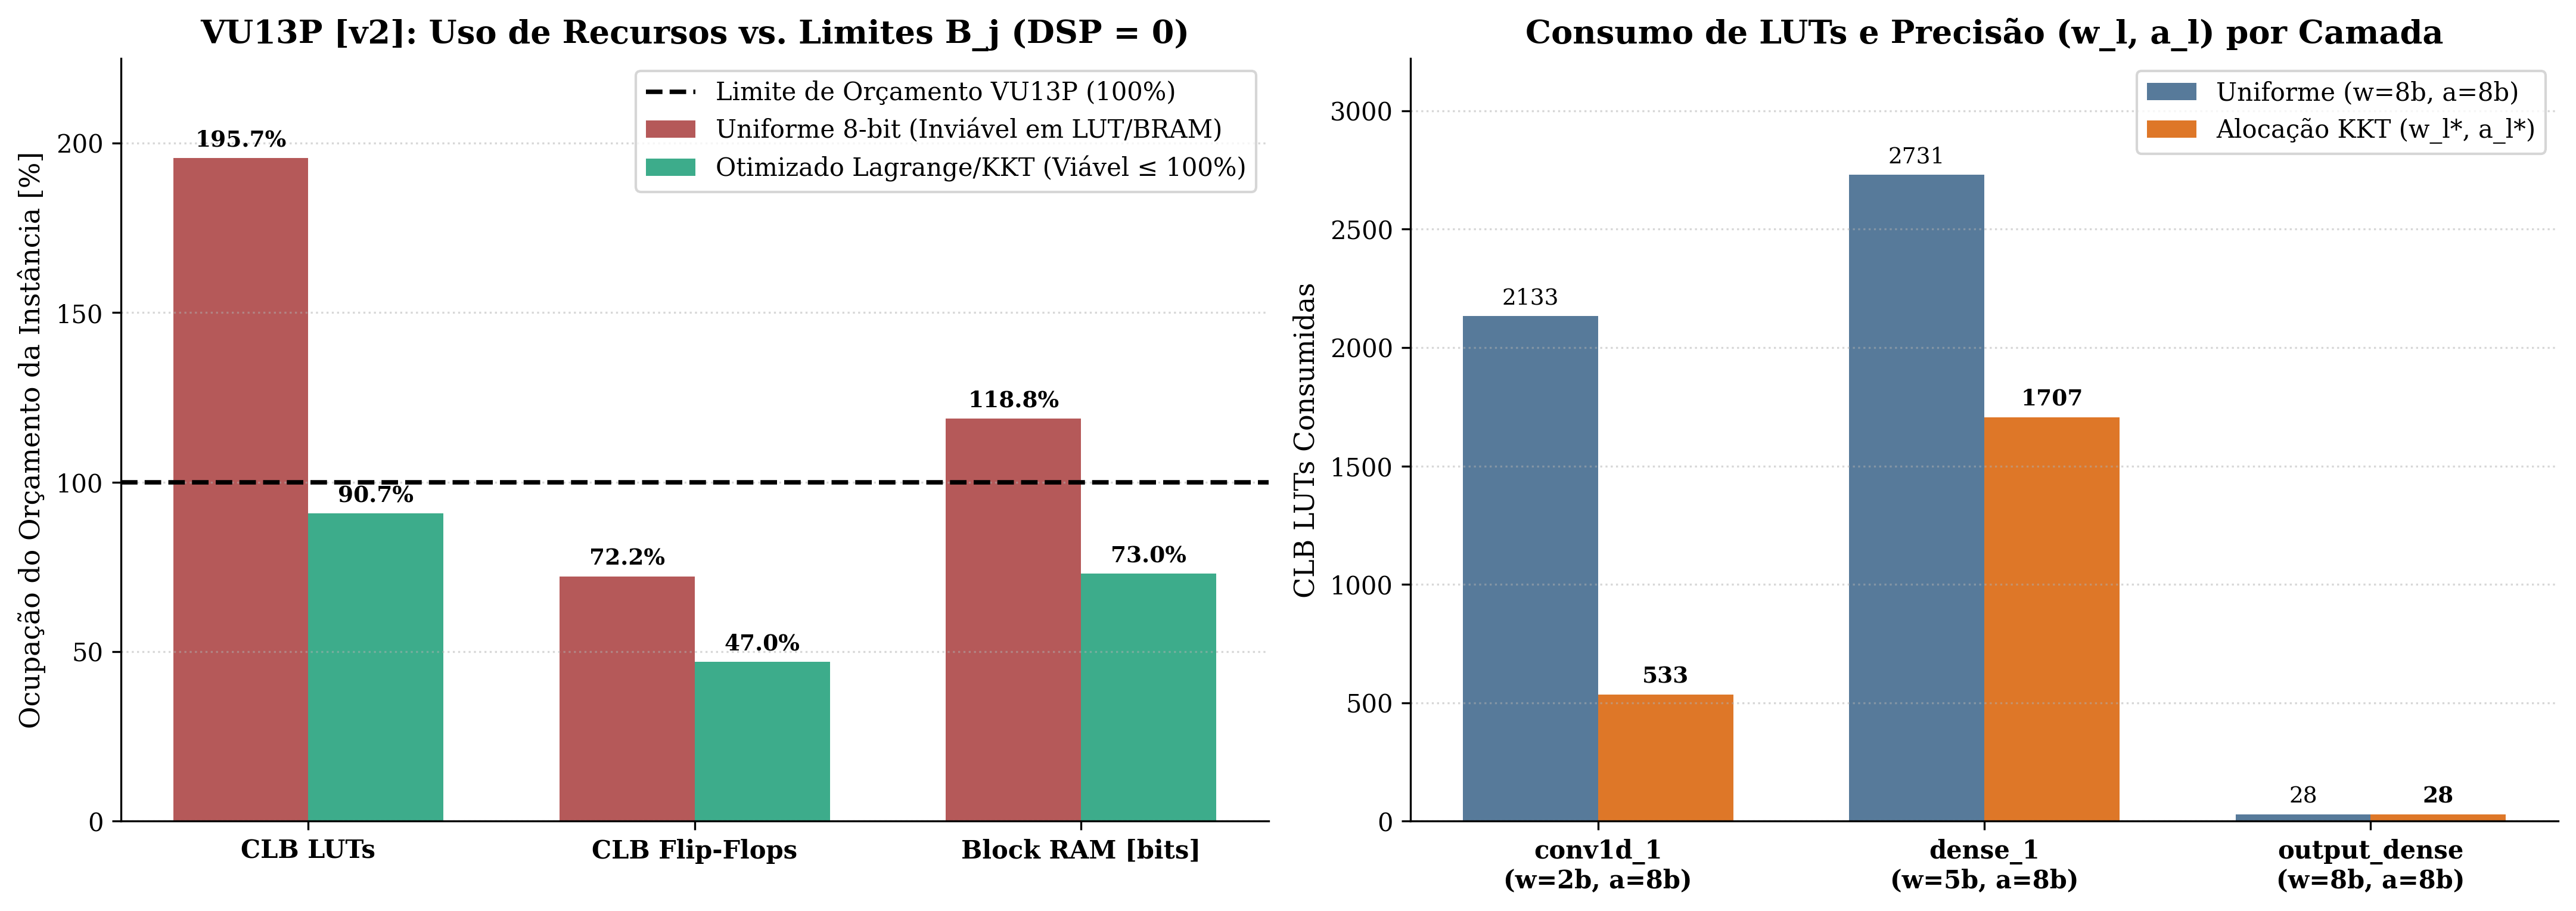


--- learning_curves.png ---


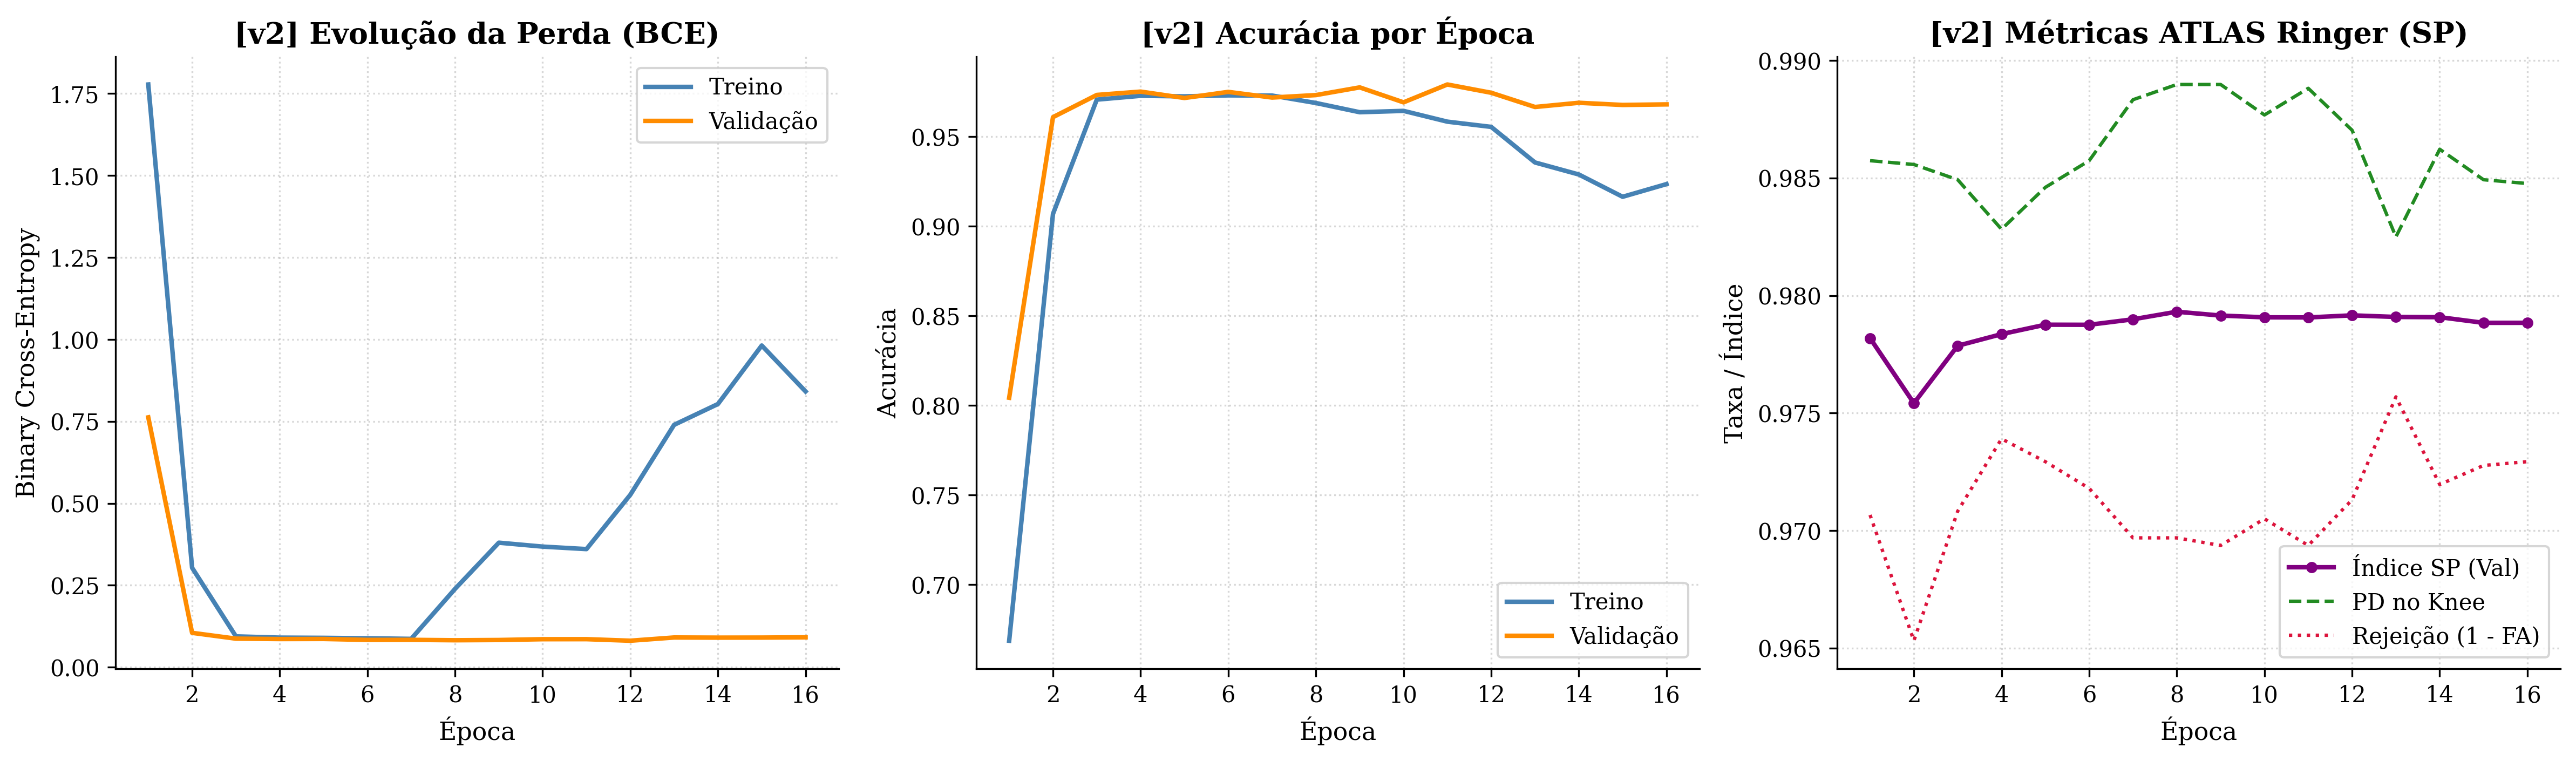


--- roc_best_model.png ---


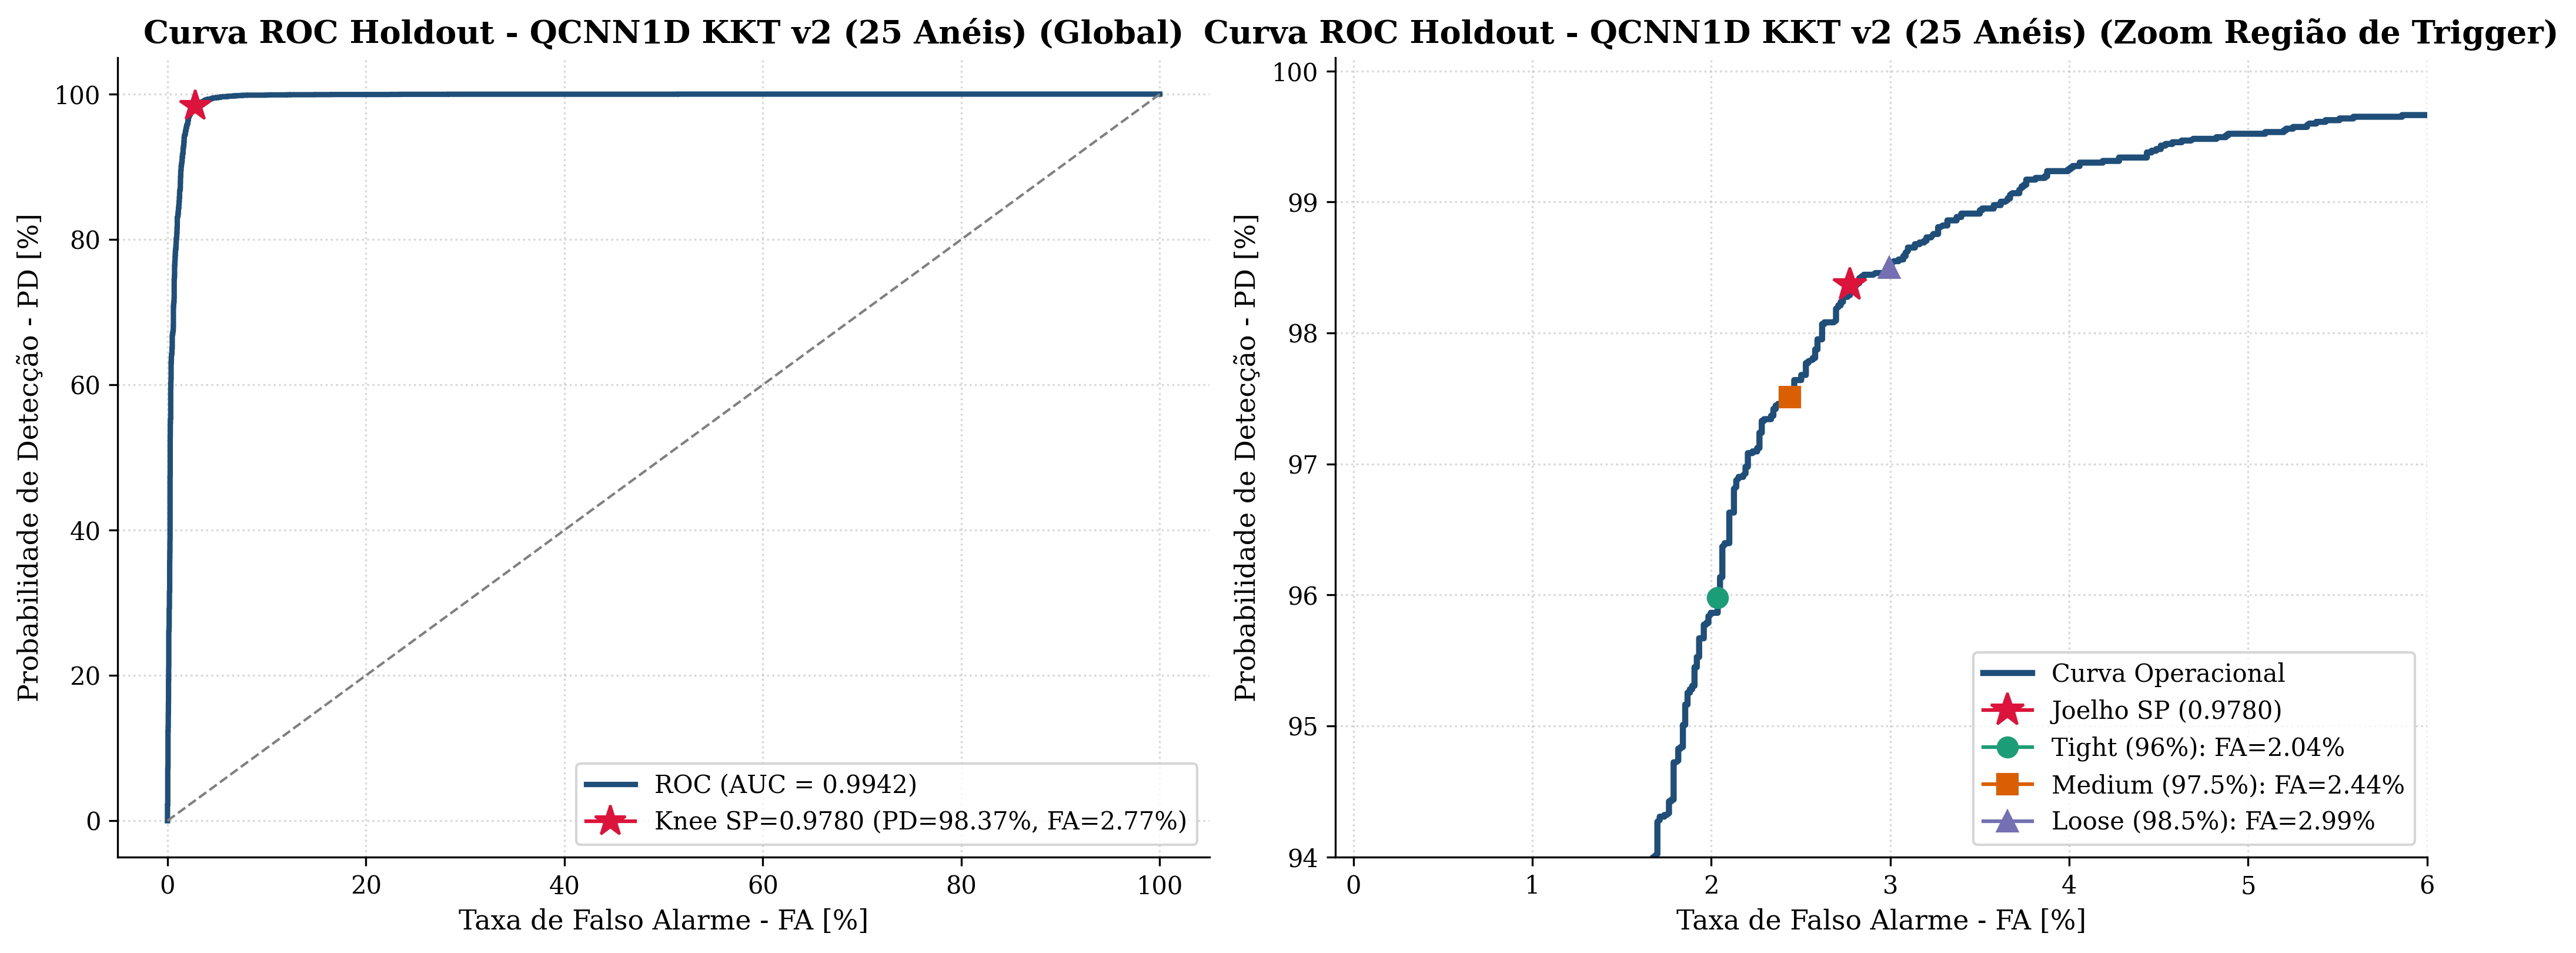


--- roc_duel_fp32_vs_kkt.png ---


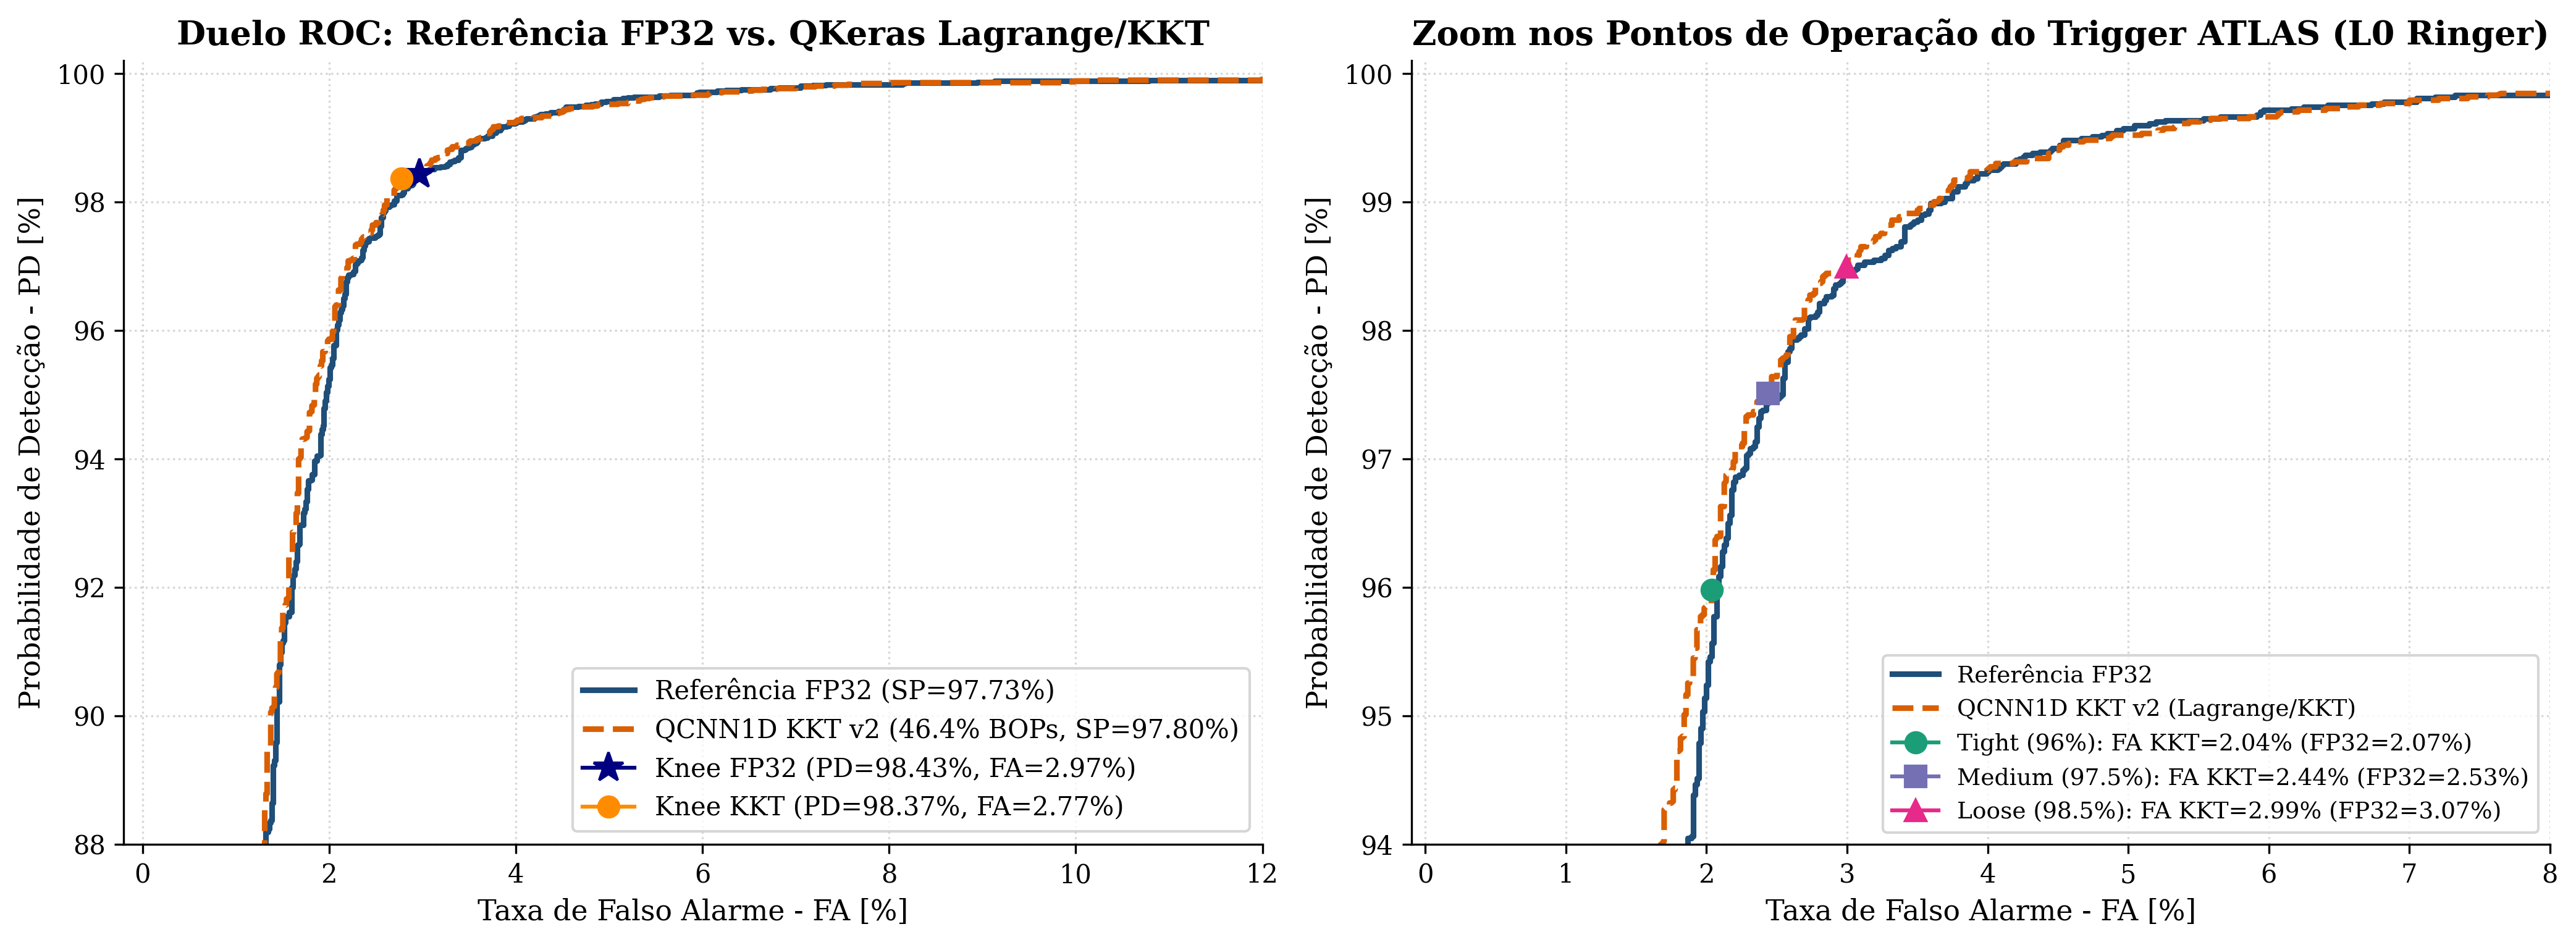


--- roc_cv_envelope.png ---


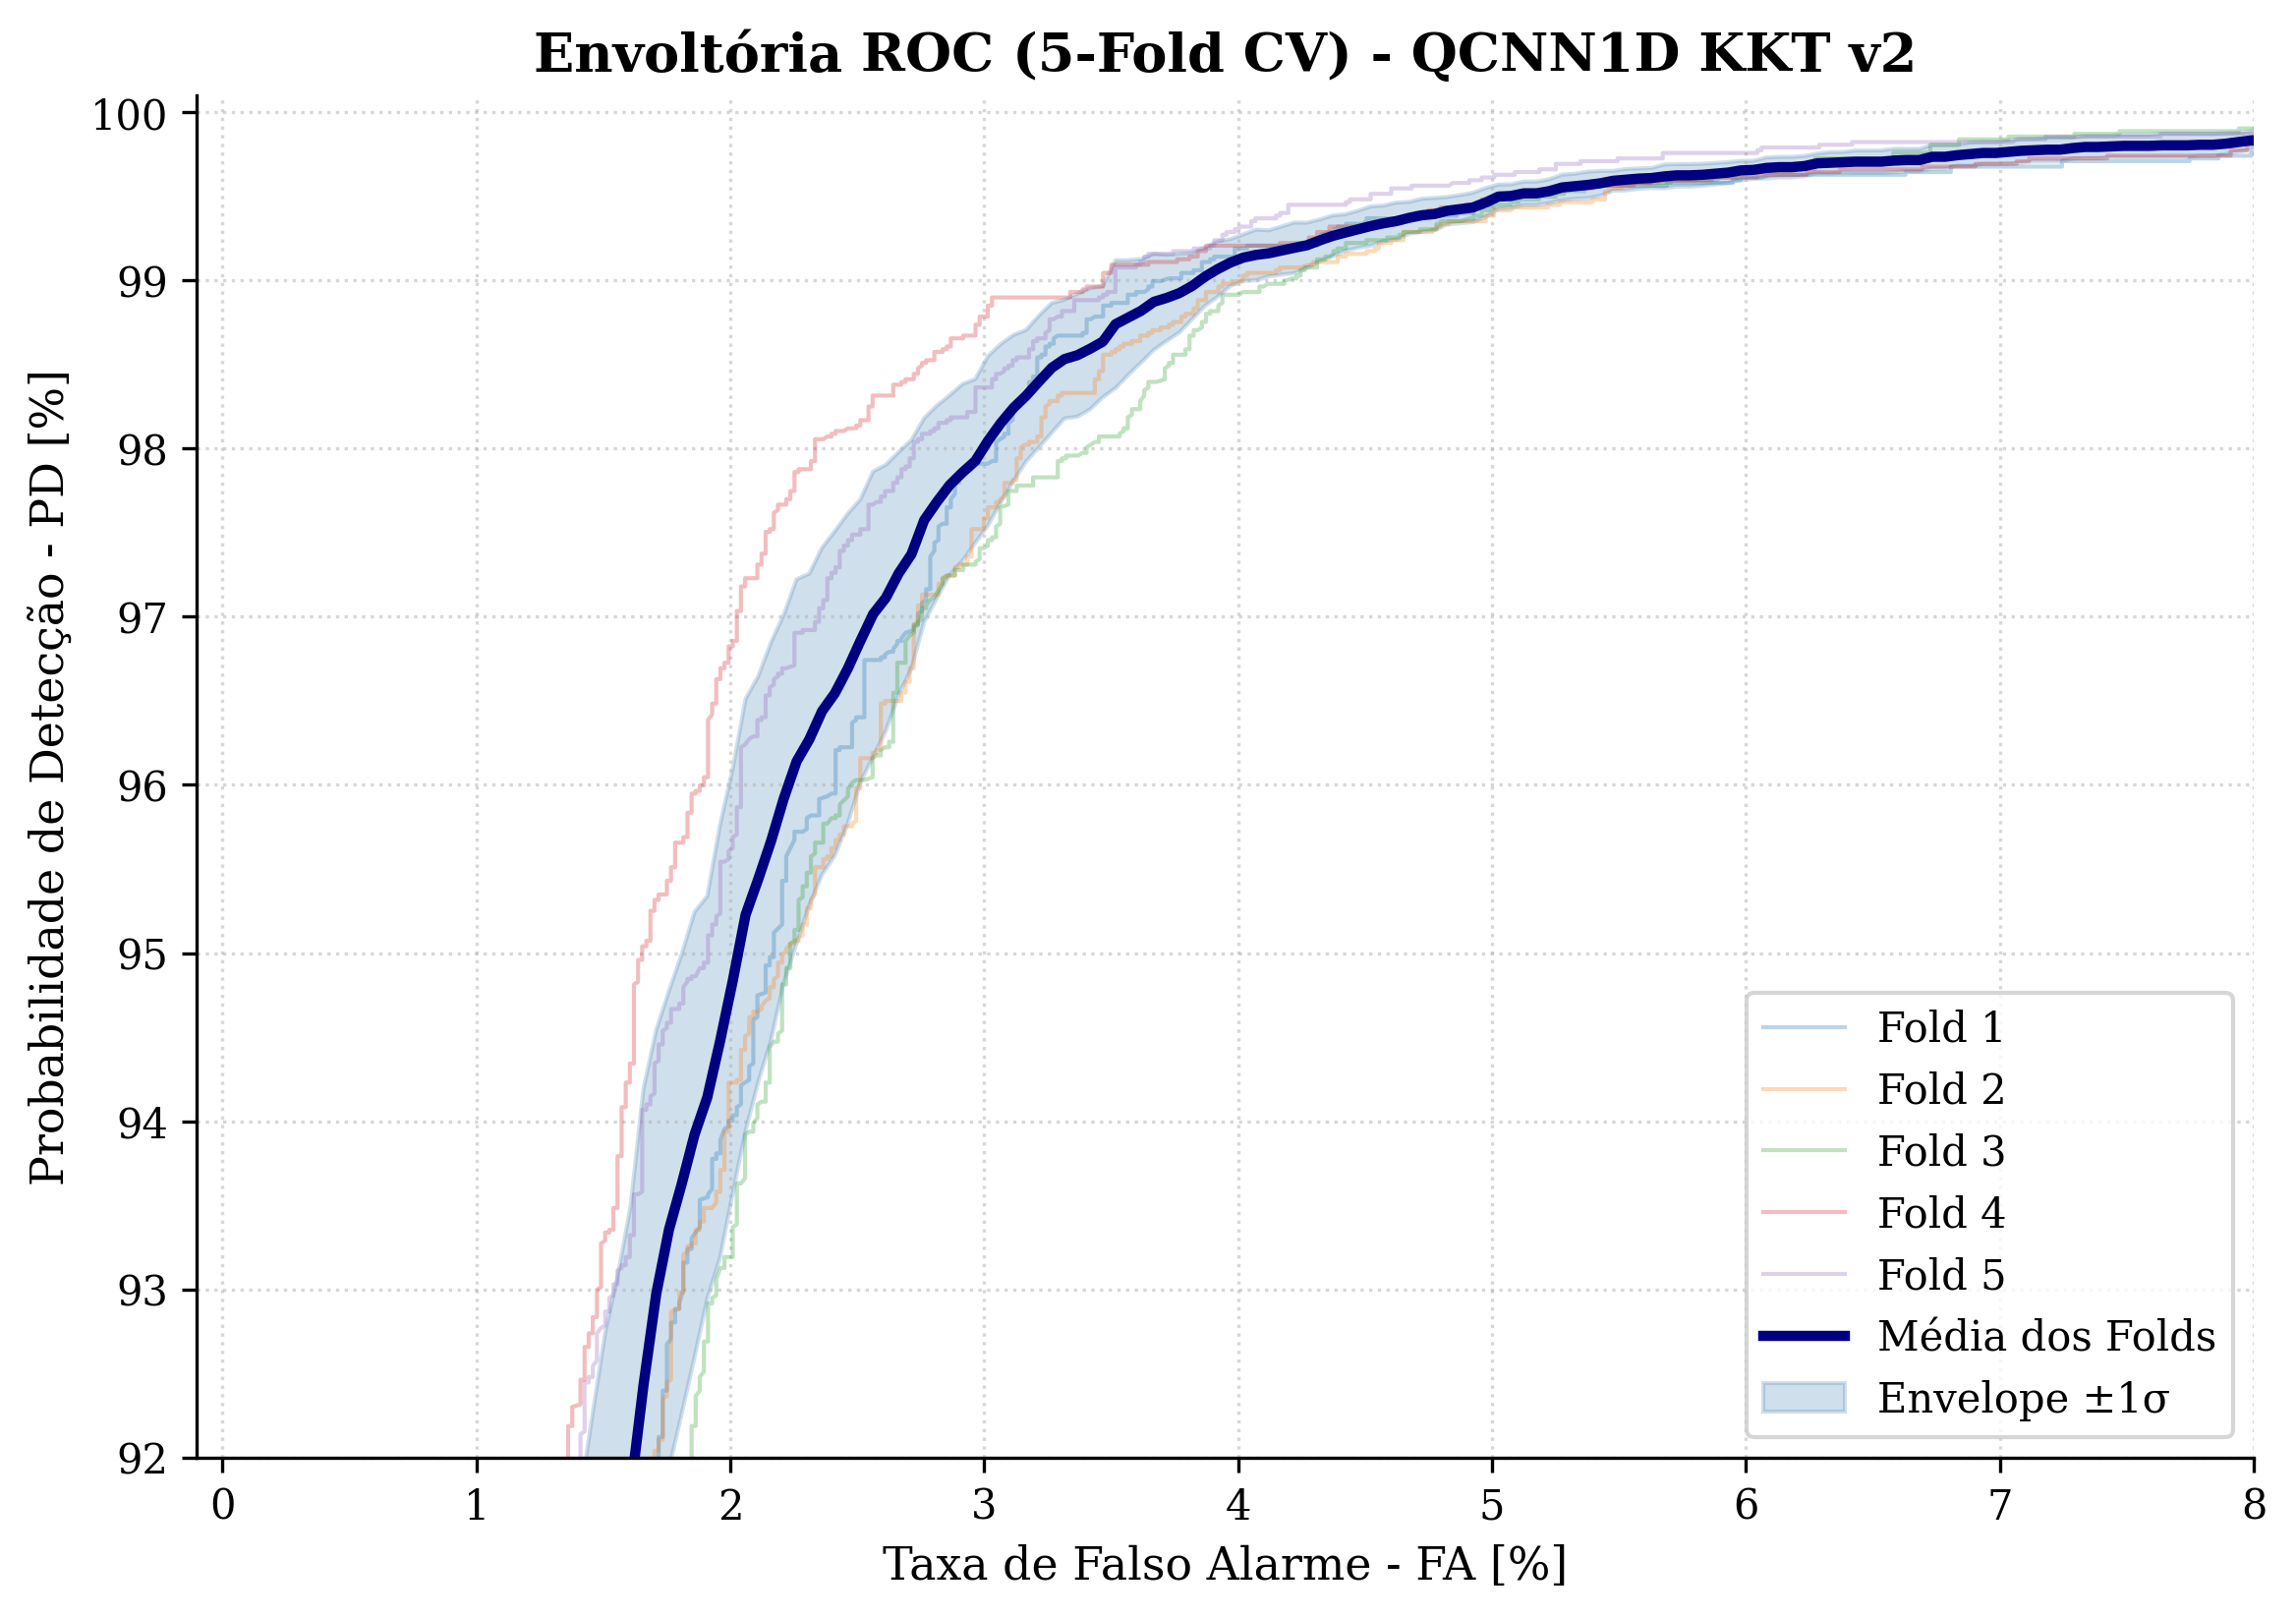


--- output_scores_hist.png ---


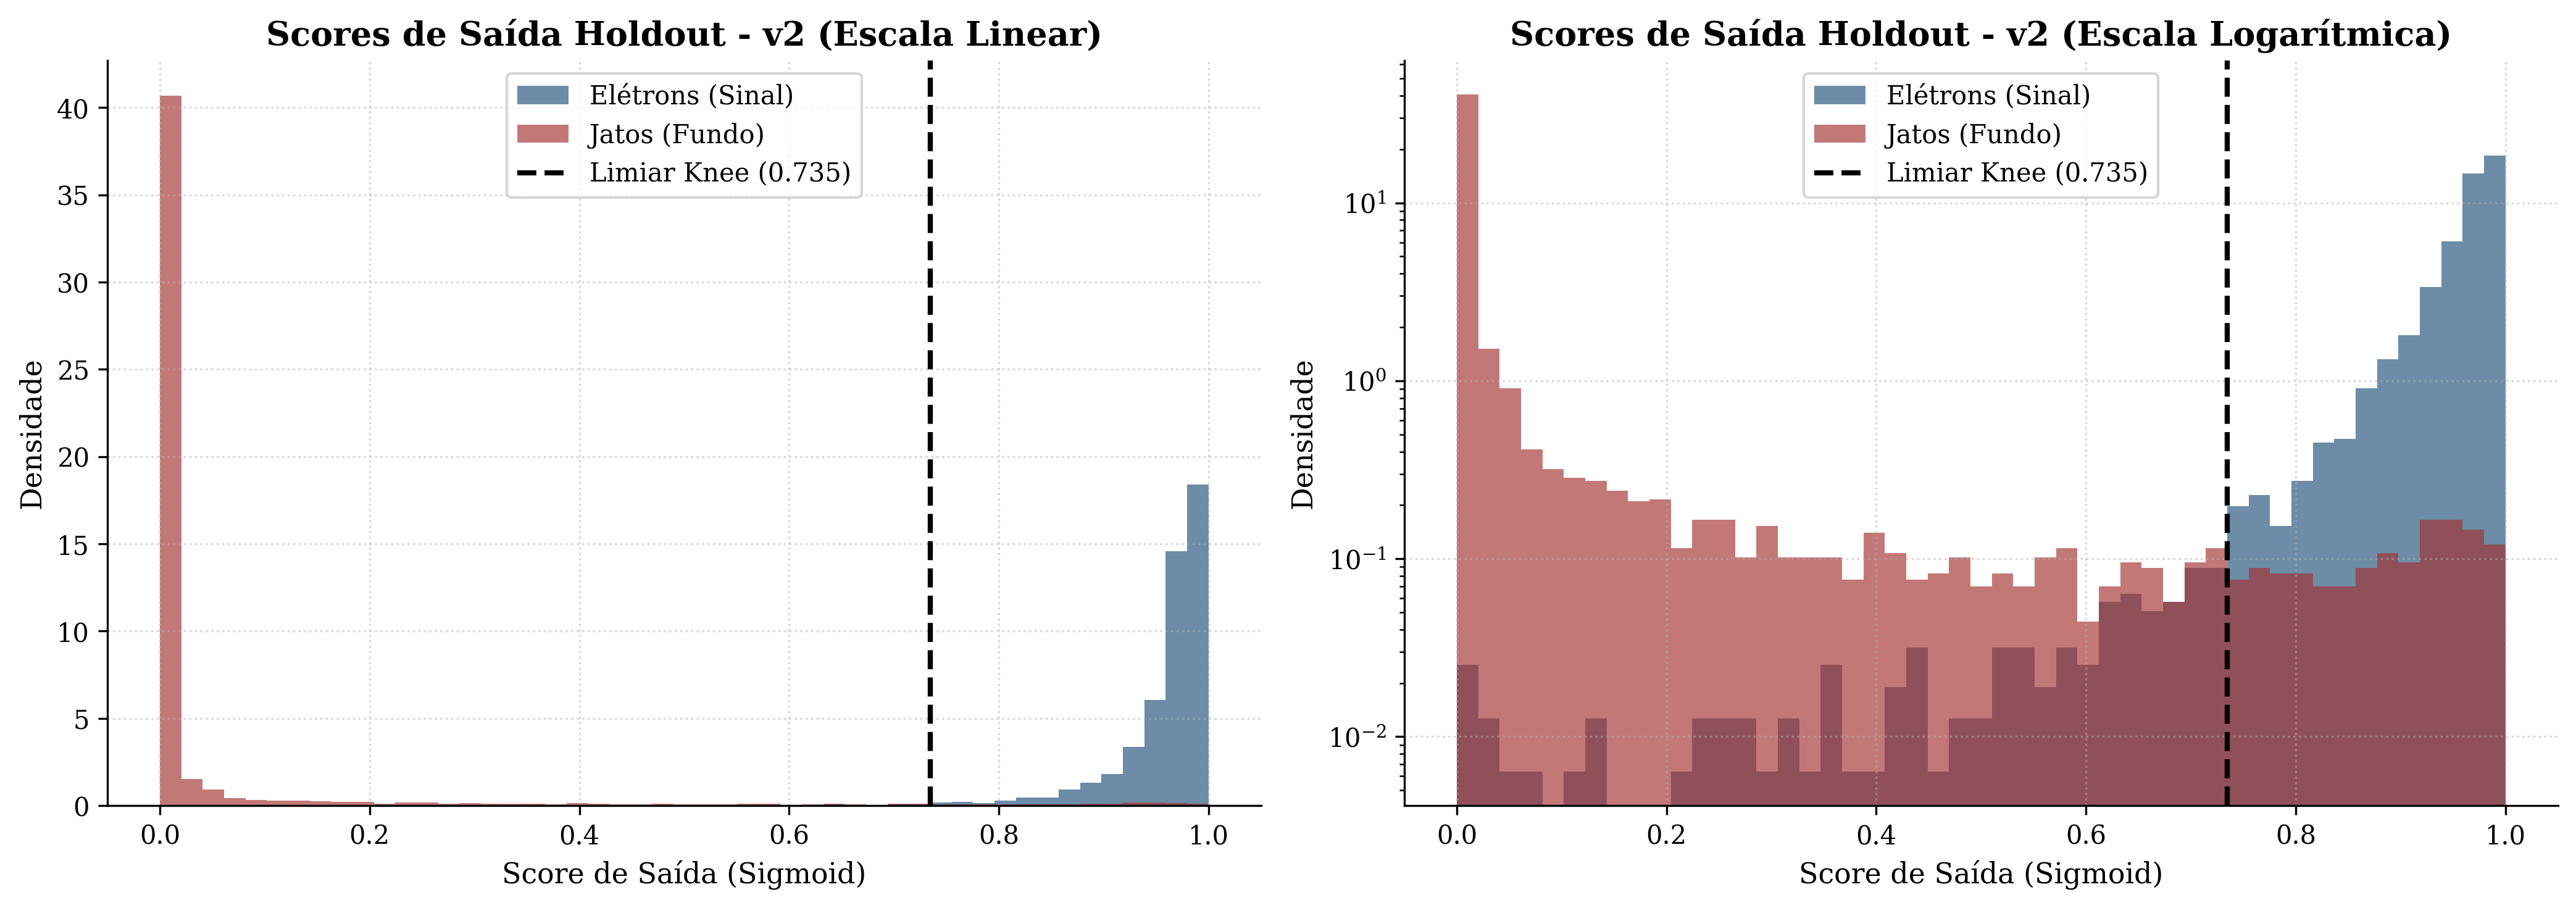


--- confusion_matrix_knee.png ---


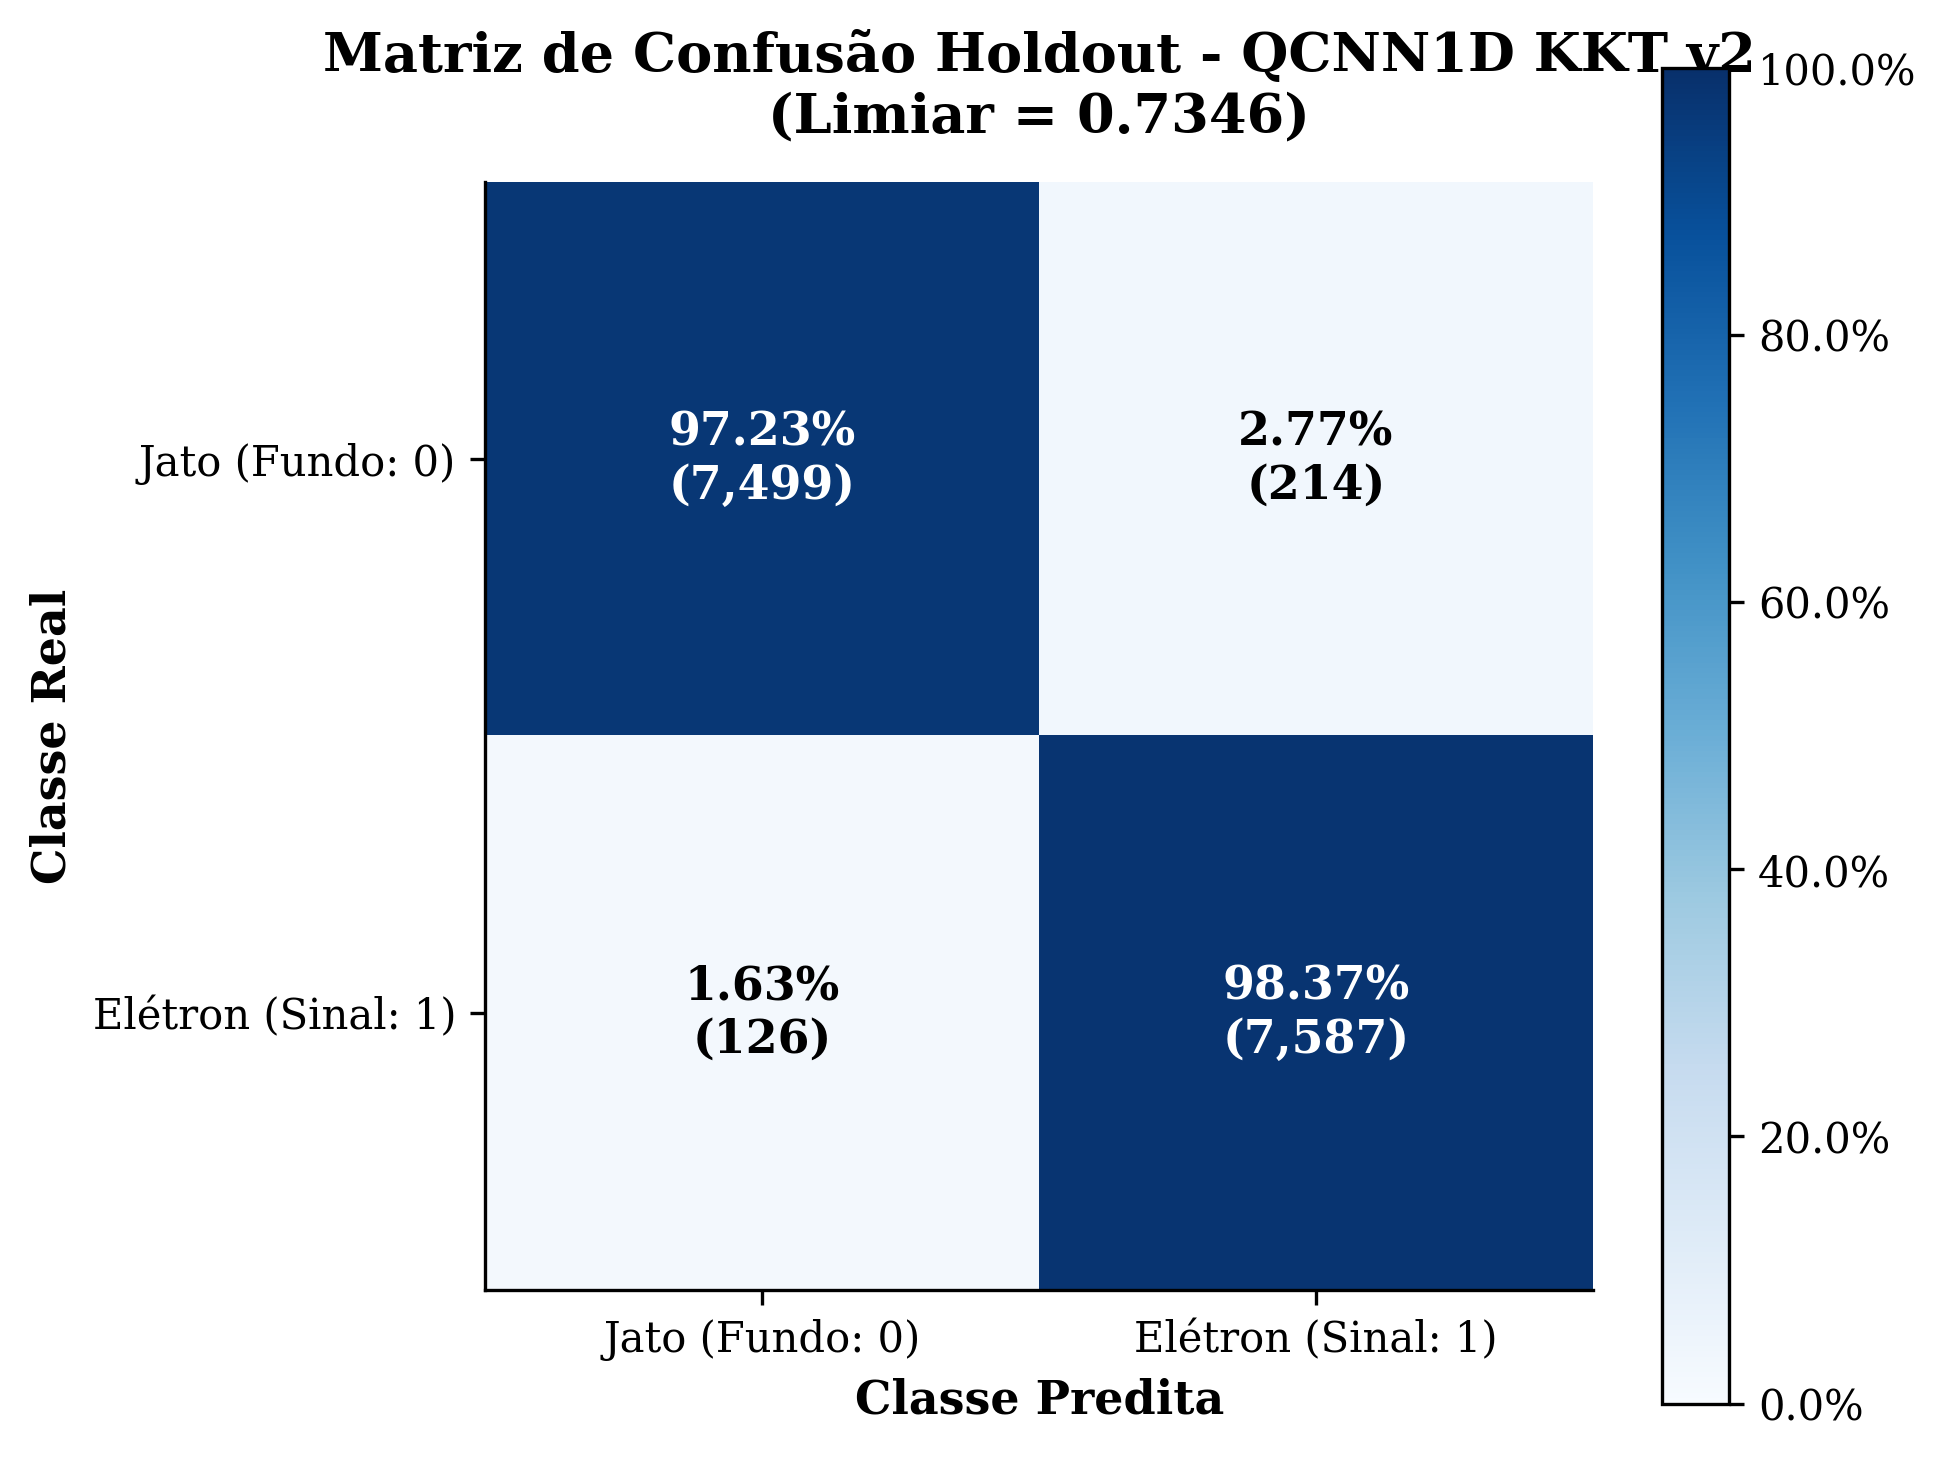


--- cv_boxplots.png ---


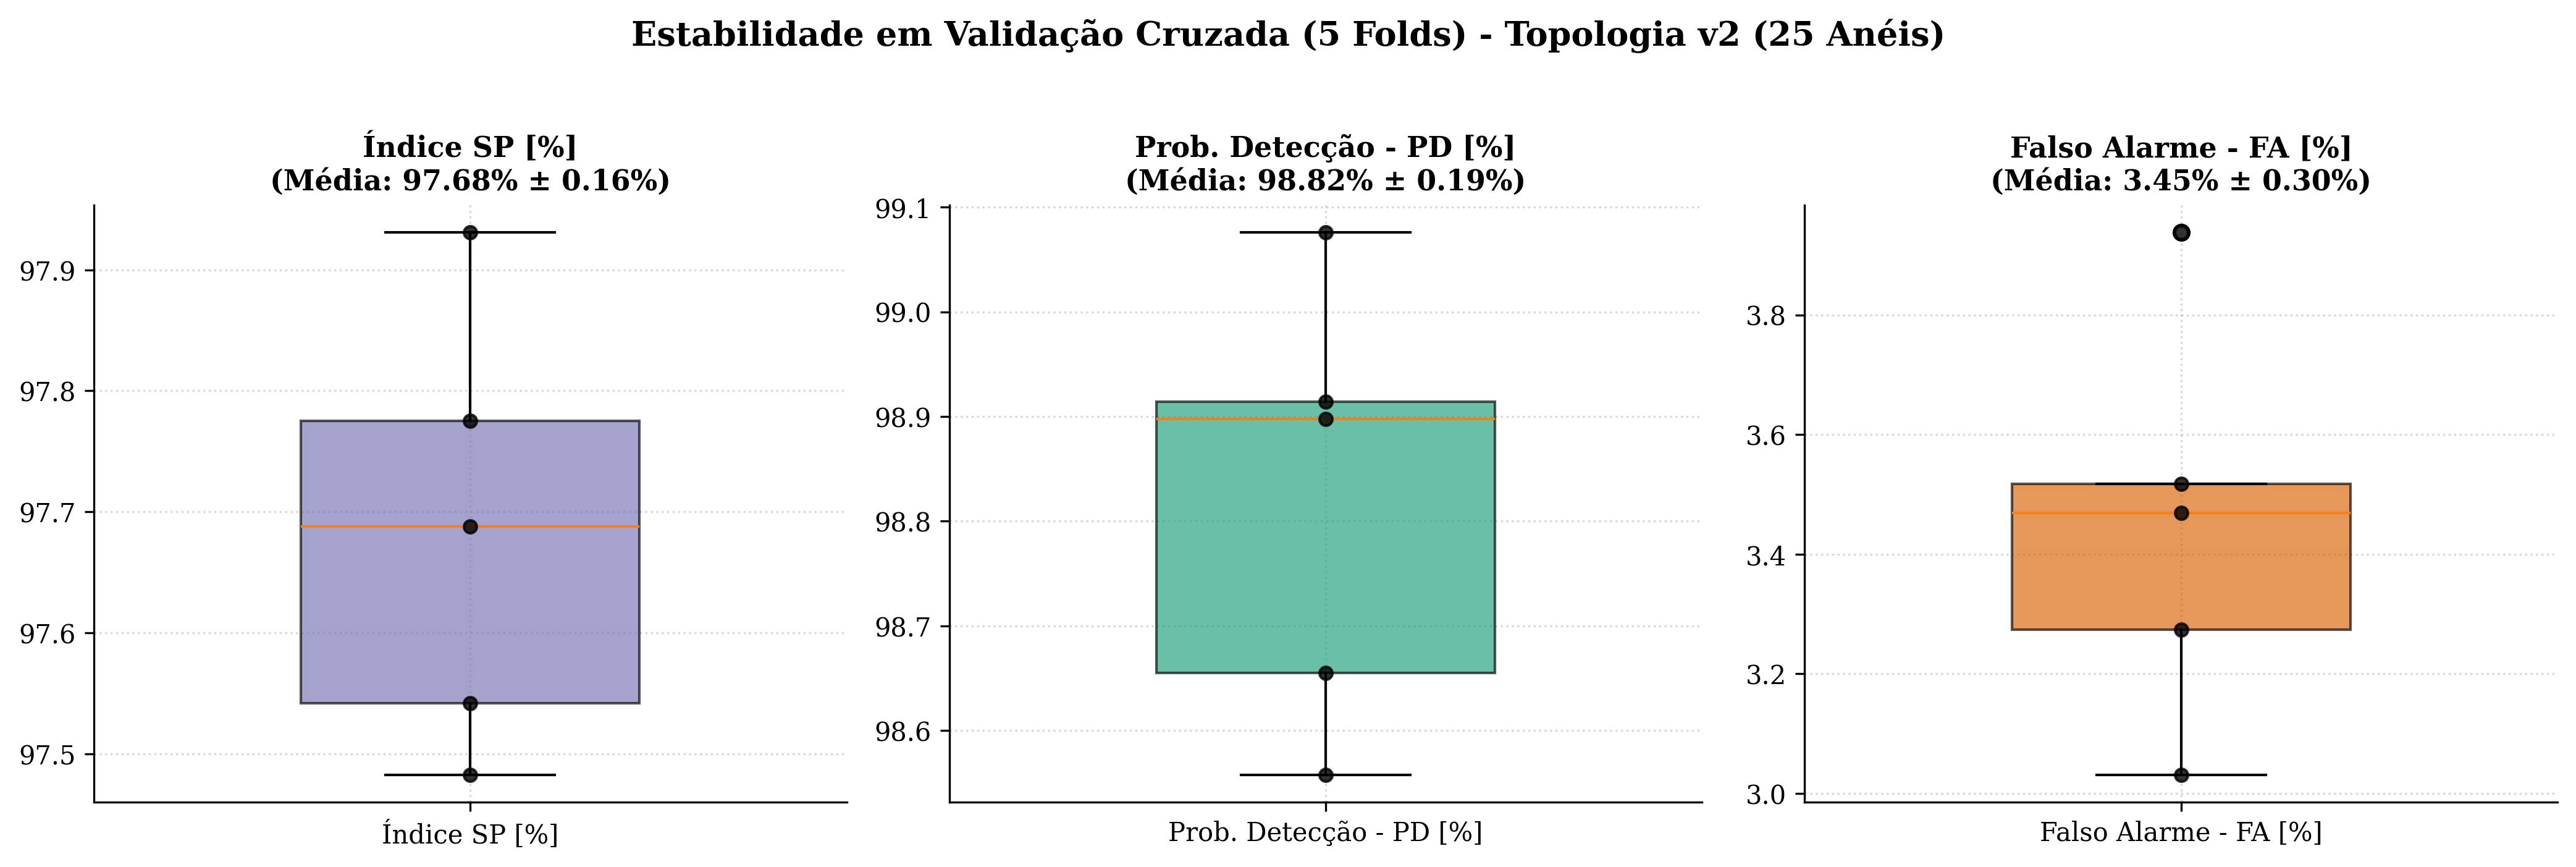


--- fa_per_fold_workpoints.png ---


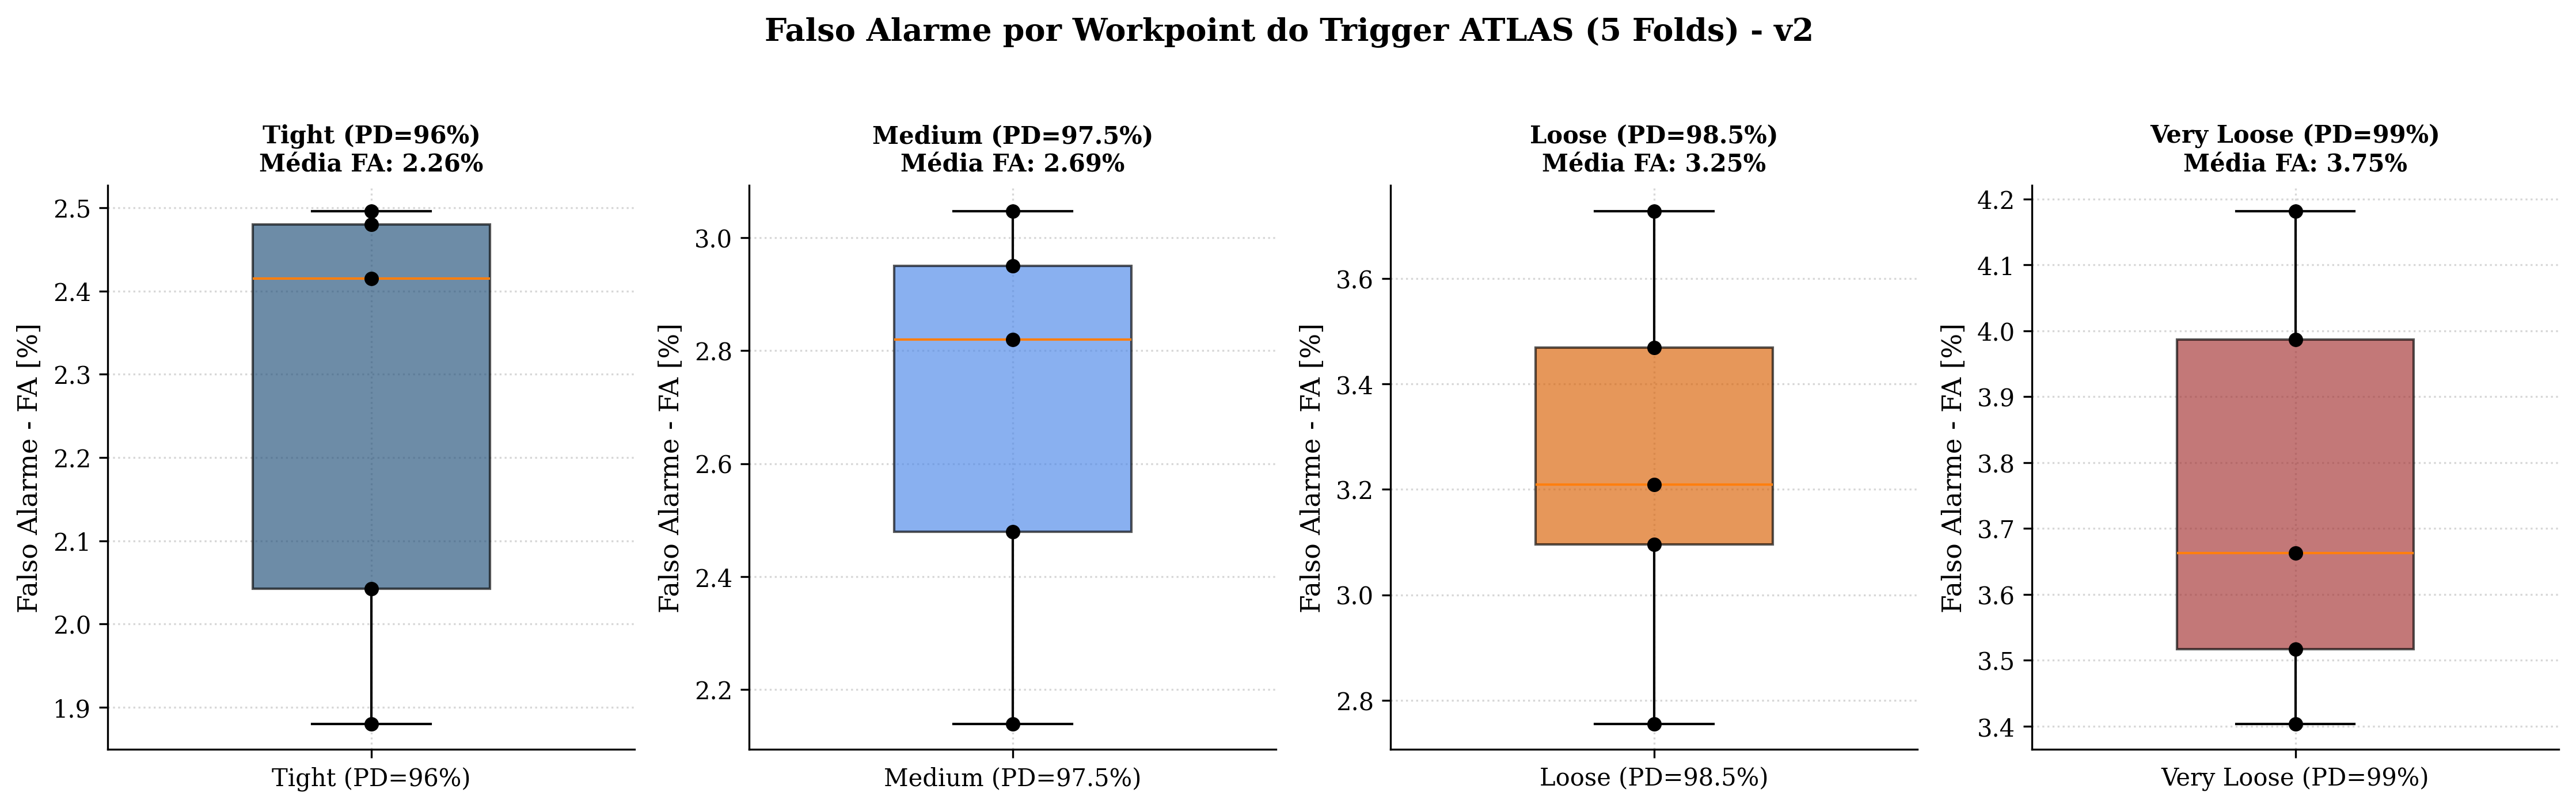

In [5]:
plots_dir = os.path.join(base_dir, "plots")
plot_files = [
    f"rings_profile_v{VERSION}.png",
    "kkt_primal_dual_evolution.png",
    "vu13p_resource_utilization.png",
    "learning_curves.png",
    "roc_best_model.png",
    "roc_duel_fp32_vs_kkt.png",
    "roc_cv_envelope.png",
    "output_scores_hist.png",
    "confusion_matrix_knee.png",
    "cv_boxplots.png",
    "fa_per_fold_workpoints.png",
]

for pfile in plot_files:
    full_p = os.path.join(plots_dir, pfile)
    if os.path.exists(full_p):
        print(f"\n--- {pfile} ---")
        display(Image(filename=full_p, width=900))
